## PARCIAL Clasificación de tuberculosis mediante audio

Universitario:   Espinoza Chiri Soledad Griselda

dataset: https://www.kaggle.com/datasets/elffff/tuberculosis-cough-acoustics-curated-dataset   
Clase de tuberculosis (positiva): proviene completamente del conjunto de datos clínicos TBscreen, que representa a pacientes con tuberculosis activa confirmados diagnosticados mediante pruebas de esputo GeneXpert/cultivo.
Clase saludable/NTB (negativa): proviene de una combinación de pacientes clínicos sin tuberculosis (TBscreen) y controles sanos de colaboración colectiva (Coswara). La incorporación de sujetos sanos de Coswara garantiza el equilibrio de clases y expone el modelo a una variedad más amplia de características de tos normal/saludable.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 0.1 Librerías

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
from scipy import optimize
import torch
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

%matplotlib inline

np.random.seed(1)


## 1. Carga del dataset



In [4]:
BASE_DIR = '/content/drive/MyDrive/SIS420/1ER_PARCIAL/audio_16k'

SPLITS = ['train', 'val', 'test']
CLASES = ['Healthy', 'TB']

def listar_audios(split, clase):
    carpeta = os.path.join(BASE_DIR, split, clase)
    archivos = [os.path.join(carpeta, f) for f in os.listdir(carpeta) if f.lower().endswith('.wav')]
    return archivos

rutas = {}
for split in SPLITS:
    for clase in CLASES:
        rutas[(split, clase)] = listar_audios(split, clase)
        print(split, clase, len(rutas[(split, clase)]))

train Healthy 313
train TB 522
val Healthy 102
val TB 127
test Healthy 66
test TB 133


### 1.1 Balance de clases



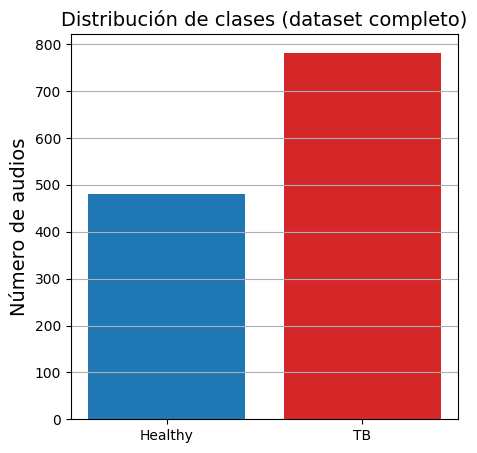

Healthy: 481 (38.1%)
TB: 782 (61.9%)


In [5]:
total_healthy = sum(len(rutas[(split, 'Healthy')]) for split in SPLITS)
total_tb = sum(len(rutas[(split, 'TB')]) for split in SPLITS)

plt.figure(figsize=(5, 5))
plt.bar(['Healthy', 'TB'], [total_healthy, total_tb], color=['tab:blue', 'tab:red'])
plt.ylabel('Número de audios', fontsize=14)
plt.title('Distribución de clases (dataset completo)', fontsize=14)
plt.grid(True, axis='y')
plt.show()

print('Healthy:', total_healthy, '(%.1f%%)' % (100 * total_healthy / (total_healthy + total_tb)))
print('TB:', total_tb, '(%.1f%%)' % (100 * total_tb / (total_healthy + total_tb)))

### 1.2 Ejemplos de audio




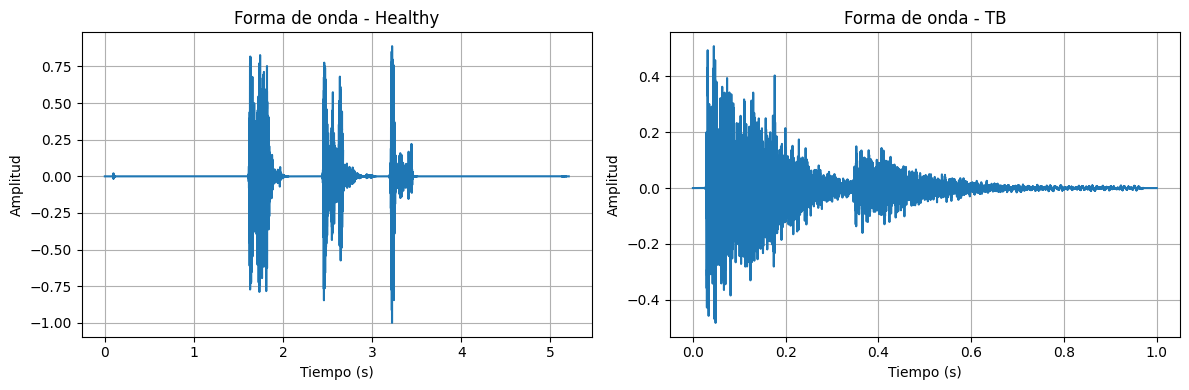

In [7]:
ejemplo_healthy = rutas[('train', 'Healthy')][0]
ejemplo_tb = rutas[('train', 'TB')][0]

senal_healthy, sr = librosa.load(ejemplo_healthy, sr=16000, mono=True)
senal_tb, sr = librosa.load(ejemplo_tb, sr=16000, mono=True)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(np.linspace(0, len(senal_healthy) / sr, len(senal_healthy)), senal_healthy)
axs[0].set_title('Forma de onda - Healthy')
axs[0].set_xlabel('Tiempo (s)')
axs[0].set_ylabel('Amplitud')
axs[0].grid(True)

axs[1].plot(np.linspace(0, len(senal_tb) / sr, len(senal_tb)), senal_tb)
axs[1].set_title('Forma de onda - TB')
axs[1].set_xlabel('Tiempo (s)')
axs[1].set_ylabel('Amplitud')
axs[1].grid(True)

plt.tight_layout()
plt.show()


## 2. Extracción de características de audio


- **MFCC** (*Mel-Frequency Cepstral Coefficients*): describen la forma del espectro en la escala perceptual Mel, muy usados para caracterizar sonidos como la voz o la tos. Se calculan 13 coeficientes.
- **RMS** (*Root Mean Square*): energía de la señal.
- **Zero Crossing Rate**: cuántas veces por segundo la señal cruza el cero, relacionado con la "rugosidad" del sonido.
- **Spectral Centroid**: "centro de masa" del espectro, relacionado con el brillo del sonido.
- **Spectral Bandwidth**: dispersión del espectro alrededor del centroide.
- **Spectral Rolloff**: frecuencia bajo la cual se concentra el 85% de la energía espectral.


In [8]:
def extraer_caracteristicas(ruta, sr=16000, n_mfcc=13):
    senal, sr = librosa.load(ruta, sr=sr, mono=True)

    mfcc = librosa.feature.mfcc(y=senal, sr=sr, n_mfcc=n_mfcc)
    rms = librosa.feature.rms(y=senal)
    zcr = librosa.feature.zero_crossing_rate(y=senal)
    centroid = librosa.feature.spectral_centroid(y=senal, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(y=senal, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(y=senal, sr=sr)

    vector = np.hstack([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        rms.mean(axis=1), rms.std(axis=1),
        zcr.mean(axis=1), zcr.std(axis=1),
        centroid.mean(axis=1), centroid.std(axis=1),
        bandwidth.mean(axis=1), bandwidth.std(axis=1),
        rolloff.mean(axis=1), rolloff.std(axis=1)
    ])

    return vector

In [9]:
FEATURES_DIR = '/content/drive/MyDrive/SIS420/1ER_PARCIAL/features'
os.makedirs(FEATURES_DIR, exist_ok=True)

def construir_dataset(split):
    archivo_X = os.path.join(FEATURES_DIR, f'X_{split}.npy')
    archivo_y = os.path.join(FEATURES_DIR, f'y_{split}.npy')

    if os.path.exists(archivo_X) and os.path.exists(archivo_y):
        return np.load(archivo_X), np.load(archivo_y)

    vectores = []
    etiquetas = []
    for clase in CLASES:
        etiqueta = CLASES.index(clase)
        for ruta in rutas[(split, clase)]:
            vectores.append(extraer_caracteristicas(ruta))
            etiquetas.append(etiqueta)

    X = np.array(vectores)
    y = np.array(etiquetas)

    np.save(archivo_X, X)
    np.save(archivo_y, y)

    return X, y

In [10]:
X_train, y_train = construir_dataset('train')
X_val, y_val = construir_dataset('val')
X_test, y_test = construir_dataset('test')

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(835, 36) (835,)
(229, 36) (229,)
(199, 36) (199,)


### 2.1 Visualización de las características extraídas



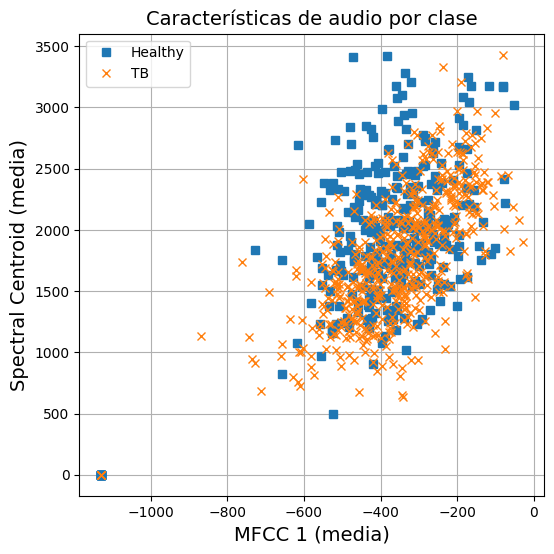

In [12]:
plt.figure(figsize=(6, 6))
plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 30], 's', label='Healthy')
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 30], 'x', label='TB')
plt.xlabel('MFCC 1 (media)', fontsize=14)
plt.ylabel('Spectral Centroid (media)', fontsize=14)
plt.title('Características de audio por clase', fontsize=14)
plt.grid(True)
plt.legend()
plt.show()

## 3. Normalización



In [13]:
def featureNormalize(X, mu=None, sigma=None):
    if mu is None:
        mu = np.mean(X, axis=0)
    if sigma is None:
        sigma = np.std(X, axis=0)

    sigma = np.where(sigma == 0, 1, sigma)
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma


In [14]:
X_train_norm, mu, sigma = featureNormalize(X_train)
X_val_norm, _, _ = featureNormalize(X_val, mu, sigma)
X_test_norm, _, _ = featureNormalize(X_test, mu, sigma)

## 4. Métricas de evaluación


In [15]:
def accuracy(y_pred, y):
    return np.sum(y_pred == y) / len(y)

def precision(y_pred, y):
    TP = np.sum((y_pred == 1) & (y == 1))
    FP = np.sum((y_pred == 1) & (y == 0))
    return TP / (TP + FP)

def recall(y_pred, y):
    TP = np.sum((y_pred == 1) & (y == 1))
    FN = np.sum((y_pred == 0) & (y == 1))
    return TP / (TP + FN)

def f1(y_pred, y):
    p = precision(y_pred, y)
    r = recall(y_pred, y)
    return 2 * (p * r) / (p + r)

In [16]:
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0, 1, 0, 1])
    plt.xlabel('FPR')
    plt.ylabel('TPR')
    plt.grid(True)

def mostrar_metricas(nombre, y, y_pred, y_score, graficar_matriz=True):
    acc = accuracy(y_pred, y)
    prec = precision(y_pred, y)
    rec = recall(y_pred, y)
    f1_ = f1(y_pred, y)
    auc = roc_auc_score(y, y_score)

    print(nombre)
    print(f'Accuracy : {acc:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'Recall   : {rec:.4f}')
    print(f'F1-score : {f1_:.4f}')
    print(f'AUC      : {auc:.4f}')
    print('Matriz de confusión:')
    cm = confusion_matrix(y, y_pred)
    print(cm)

    if graficar_matriz:
        plt.figure(figsize=(4, 4))
        plt.imshow(cm, interpolation='nearest')
        plt.title(f'Matriz de confusión - {nombre}')
        plt.colorbar()
        plt.xticks([0, 1], ['Healthy', 'TB'])
        plt.yticks([0, 1], ['Healthy', 'TB'])
        plt.xlabel('Predicción')
        plt.ylabel('Real')
        for i in range(2):
            for j in range(2):
                plt.text(j, i, cm[i, j], ha='center', va='center')
        plt.tight_layout()
        plt.show()

    return {'modelo': nombre, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1_, 'auc': auc}

resultados = []


## 5. Modelo 1: Regresión Logística



In [17]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

In [18]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def costFunctionReg(theta, X, y, lambda_):
    m = y.size
    h = sigmoid(X.dot(theta))
    h = np.clip(h, 1e-10, 1 - 1e-10)

    temp = theta.copy()
    temp[0] = 0

    J = (1 / m) * np.sum(-y * np.log(h) - (1 - y) * np.log(1 - h)) \
        + (lambda_ / (2 * m)) * np.sum(np.square(temp))
    grad = (1 / m) * X.T.dot(h - y) + (lambda_ / m) * temp

    return J, grad


Costo inicial: 0.6931471805599453
Costo final: 0.4735628933057393


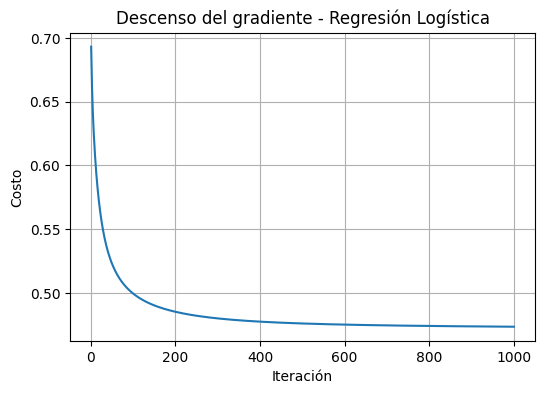

In [19]:
m_train = X_train_norm.shape[0]
X_train_b = np.concatenate([np.ones((m_train, 1)), X_train_norm], axis=1)

m_val = X_val_norm.shape[0]
X_val_b = np.concatenate([np.ones((m_val, 1)), X_val_norm], axis=1)

m_test = X_test_norm.shape[0]
X_test_b = np.concatenate([np.ones((m_test, 1)), X_test_norm], axis=1)

theta = np.zeros(X_train_b.shape[1])
alpha = 0.1
lambda_ = 1
iterations = 1000
cost_history = []

for i in range(iterations):
    J, grad = costFunctionReg(theta, X_train_b, y_train, lambda_)
    theta = theta - alpha * grad
    cost_history.append(J)

print('Costo inicial:', cost_history[0])
print('Costo final:', cost_history[-1])

plt.figure(figsize=(6, 4))
plt.plot(range(1, iterations + 1), cost_history)
plt.xlabel('Iteración')
plt.ylabel('Costo')
plt.title('Descenso del gradiente - Regresión Logística')
plt.grid(True)
plt.show()


Regresión Logística (val)
Accuracy : 0.6507
Precision: 0.6577
Recall   : 0.7717
F1-score : 0.7101
AUC      : 0.6237
Matriz de confusión:
[[51 51]
 [29 98]]


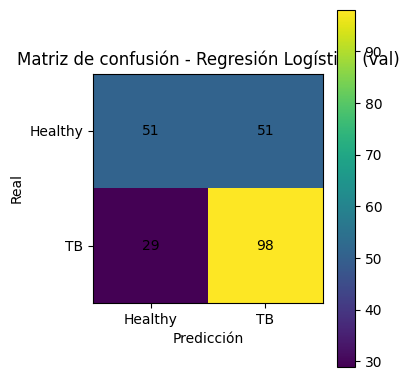

Regresión Logística (test)
Accuracy : 0.7638
Precision: 0.8071
Recall   : 0.8496
F1-score : 0.8278
AUC      : 0.7370
Matriz de confusión:
[[ 39  27]
 [ 20 113]]


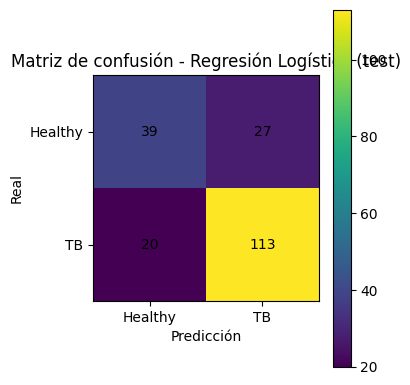

In [20]:
def predict_logreg(theta, X):
    return sigmoid(X.dot(theta))

y_score_val_lr = predict_logreg(theta, X_val_b)
y_pred_val_lr = (y_score_val_lr >= 0.5).astype(int)

y_score_test_lr = predict_logreg(theta, X_test_b)
y_pred_test_lr = (y_score_test_lr >= 0.5).astype(int)

resultados.append(mostrar_metricas('Regresión Logística (val)', y_val, y_pred_val_lr, y_score_val_lr))
resultados.append(mostrar_metricas('Regresión Logística (test)', y_test, y_pred_test_lr, y_score_test_lr))


## 6. Modelo 2: Red Neuronal manual (NumPy)



In [21]:
def sigmoidGradient(z):
    return sigmoid(z) * (1 - sigmoid(z))

In [22]:
def nnCostFunction(nn_params, input_layer_size, hidden_layer_size, num_labels, X, y, lambda_=0.0):
    Theta1 = np.reshape(nn_params[:hidden_layer_size * (input_layer_size + 1)], (hidden_layer_size, (input_layer_size + 1)))
    Theta2 = np.reshape(nn_params[(hidden_layer_size * (input_layer_size + 1)):], (num_labels, (hidden_layer_size + 1)))

    m = y.size

    a1 = np.concatenate([np.ones((m, 1)), X], axis=1)
    a2 = sigmoid(a1.dot(Theta1.T))
    a2 = np.concatenate([np.ones((a2.shape[0], 1)), a2], axis=1)
    a3 = sigmoid(a2.dot(Theta2.T))

    y_matrix = np.eye(num_labels)[y]

    reg_term = (lambda_ / (2 * m)) * (np.sum(np.square(Theta1[:, 1:])) + np.sum(np.square(Theta2[:, 1:])))
    J = (-1 / m) * np.sum((np.log(a3) * y_matrix) + np.log(1 - a3) * (1 - y_matrix)) + reg_term

    delta_3 = a3 - y_matrix
    delta_2 = delta_3.dot(Theta2)[:, 1:] * sigmoidGradient(a1.dot(Theta1.T))

    Delta1 = delta_2.T.dot(a1)
    Delta2 = delta_3.T.dot(a2)

    Theta1_grad = (1 / m) * Delta1
    Theta1_grad[:, 1:] = Theta1_grad[:, 1:] + (lambda_ / m) * Theta1[:, 1:]

    Theta2_grad = (1 / m) * Delta2
    Theta2_grad[:, 1:] = Theta2_grad[:, 1:] + (lambda_ / m) * Theta2[:, 1:]

    grad = np.concatenate([Theta1_grad.ravel(), Theta2_grad.ravel()])

    return J, grad

In [23]:
def randInitializeWeights(L_in, L_out, epsilon_init=0.12):
    return np.random.rand(L_out, 1 + L_in) * 2 * epsilon_init - epsilon_init

In [24]:
input_layer_size = X_train_norm.shape[1]
hidden_layer_size = 20
num_labels = 2

initial_Theta1 = randInitializeWeights(input_layer_size, hidden_layer_size)
initial_Theta2 = randInitializeWeights(hidden_layer_size, num_labels)
initial_nn_params = np.concatenate([initial_Theta1.ravel(), initial_Theta2.ravel()])

lambda_nn = 1
options = {'maxiter': 400}
costFunction = lambda p: nnCostFunction(p, input_layer_size, hidden_layer_size, num_labels, X_train_norm, y_train, lambda_nn)

res = optimize.minimize(costFunction, initial_nn_params, jac=True, method='TNC', options=options)
nn_params = res.x

Theta1 = np.reshape(nn_params[:hidden_layer_size * (input_layer_size + 1)], (hidden_layer_size, (input_layer_size + 1)))
Theta2 = np.reshape(nn_params[(hidden_layer_size * (input_layer_size + 1)):], (num_labels, (hidden_layer_size + 1)))

print('Costo final:', res.fun)

/tmp/ipykernel_4645/425021709.py:13: OptimizeWarning: Unknown solver options: maxiter
  res = optimize.minimize(costFunction, initial_nn_params, jac=True, method='TNC', options=options)


Costo final: 0.43702384326818067


Red Neuronal NumPy (val)
Accuracy : 0.6507
Precision: 0.6478
Recall   : 0.8110
F1-score : 0.7203
AUC      : 0.6640
Matriz de confusión:
[[ 46  56]
 [ 24 103]]


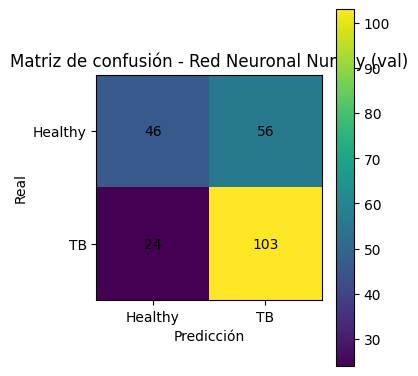

Red Neuronal NumPy (test)
Accuracy : 0.6935
Precision: 0.7769
Recall   : 0.7594
F1-score : 0.7681
AUC      : 0.7143
Matriz de confusión:
[[ 37  29]
 [ 32 101]]


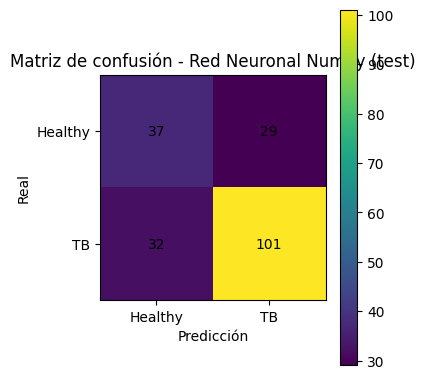

In [25]:
def forward_nn(Theta1, Theta2, X):
    m = X.shape[0]
    a1 = np.concatenate([np.ones((m, 1)), X], axis=1)
    a2 = sigmoid(a1.dot(Theta1.T))
    a2 = np.concatenate([np.ones((a2.shape[0], 1)), a2], axis=1)
    a3 = sigmoid(a2.dot(Theta2.T))
    return a3

a3_val = forward_nn(Theta1, Theta2, X_val_norm)
y_pred_val_nn = np.argmax(a3_val, axis=1)
y_score_val_nn = a3_val[:, 1]

a3_test = forward_nn(Theta1, Theta2, X_test_norm)
y_pred_test_nn = np.argmax(a3_test, axis=1)
y_score_test_nn = a3_test[:, 1]

resultados.append(mostrar_metricas('Red Neuronal NumPy (val)', y_val, y_pred_val_nn, y_score_val_nn))
resultados.append(mostrar_metricas('Red Neuronal NumPy (test)', y_test, y_pred_test_nn, y_score_test_nn))

## 7. Modelo 3: Red Neuronal con Pytorch



In [26]:
class DatasetAudio(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, ix):
        return self.X[ix], self.y[ix]

dataset_train = DatasetAudio(X_train_norm, y_train)
dataloader_train = torch.utils.data.DataLoader(dataset_train, batch_size=32, shuffle=True)

In [27]:
D_in = X_train_norm.shape[1]
H = 20
D_out = 2

model = torch.nn.Sequential(
    torch.nn.Linear(D_in, H),
    torch.nn.ReLU(),
    torch.nn.Linear(H, D_out),
)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

epochs = 100
log_each = 10
l = []
model.train()
for e in range(1, epochs + 1):
    _l = []
    for x_b, y_b in dataloader_train:
        y_pred = model(x_b)
        loss = criterion(y_pred, y_b)
        _l.append(loss.item())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    l.append(np.mean(_l))
    if not e % log_each:
        print(f'Epoch {e}/{epochs} Loss {np.mean(l):.5f}')

Epoch 10/100 Loss 0.47548
Epoch 20/100 Loss 0.40573
Epoch 30/100 Loss 0.35409
Epoch 40/100 Loss 0.31559
Epoch 50/100 Loss 0.28372
Epoch 60/100 Loss 0.25946
Epoch 70/100 Loss 0.23867
Epoch 80/100 Loss 0.21984
Epoch 90/100 Loss 0.20468
Epoch 100/100 Loss 0.19223


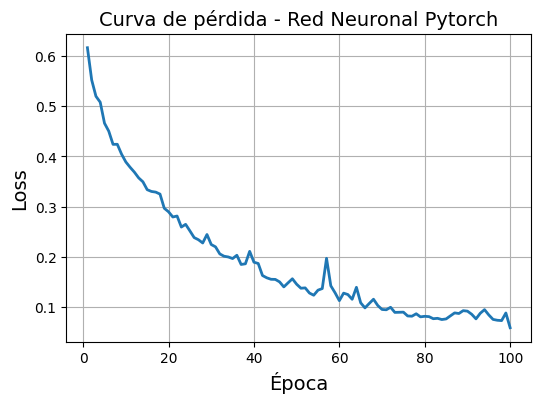

In [28]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, epochs + 1), l, lw=2)
plt.xlabel('Época', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Curva de pérdida - Red Neuronal Pytorch', fontsize=14)
plt.grid(True)
plt.show()

Red Neuronal Pytorch (val)
Accuracy : 0.6681
Precision: 0.6624
Recall   : 0.8189
F1-score : 0.7324
AUC      : 0.6459
Matriz de confusión:
[[ 49  53]
 [ 23 104]]


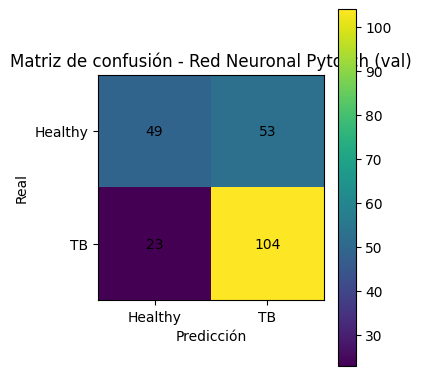

Red Neuronal Pytorch (test)
Accuracy : 0.7337
Precision: 0.7941
Recall   : 0.8120
F1-score : 0.8030
AUC      : 0.6974
Matriz de confusión:
[[ 38  28]
 [ 25 108]]


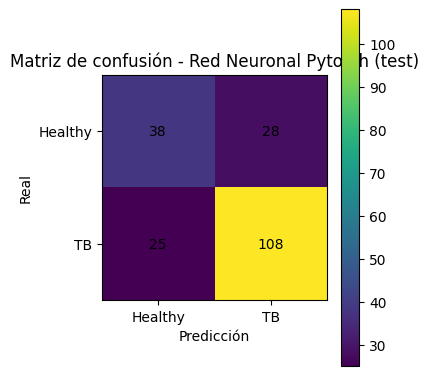

In [29]:
def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1, keepdims=True)

def evaluate_pytorch(x):
    model.eval()
    y_pred = model(x)
    y_probas = softmax(y_pred)
    return y_probas

X_val_t = torch.from_numpy(X_val_norm).float()
X_test_t = torch.from_numpy(X_test_norm).float()

probas_val = evaluate_pytorch(X_val_t).detach().numpy()
y_pred_val_pt = np.argmax(probas_val, axis=1)
y_score_val_pt = probas_val[:, 1]

probas_test = evaluate_pytorch(X_test_t).detach().numpy()
y_pred_test_pt = np.argmax(probas_test, axis=1)
y_score_test_pt = probas_test[:, 1]

resultados.append(mostrar_metricas('Red Neuronal Pytorch (val)', y_val, y_pred_val_pt, y_score_val_pt))
resultados.append(mostrar_metricas('Red Neuronal Pytorch (test)', y_test, y_pred_test_pt, y_score_test_pt))